# Schulmaterialien mit YOLOE-11 und Webcam erkennen

Das Notebook läuft ohne API-Key und ohne Roboflow-Konto. Es verwendet das frei verfügbare Ultralytics-Modell **YOLOE-11s**, eine YOLO11-Variante, der man die gewünschten Objektklassen als Text vorgibt. Die Erkennung läuft lokal. Das separat trainierte Roboflow-Modell `school_supplies_detection/1` erfordert laut Anbieter einen Schlüssel zum Laden. [Ultralytics YOLOE](https://docs.ultralytics.com/models/yoloe) · [Roboflow Inference](https://docs.roboflow.com/deployment/self-hosted/inference-library)

Die Webcam wird wie in `camera.py` mit OpenCV geöffnet. Im Notebook siehst du live Rahmen, englische Klassennamen und Konfidenzwerte. [Kameraskript im Repository](https://github.com/DanDerMan17/Snack_Detector_DSAI/blob/main/camera.py)

## 1. Jupyter lokal einrichten

Installiere Python 3.12 und Git, falls sie fehlen. Starte Jupyter auf dem Rechner, an dem die Webcam angeschlossen ist. Dazu kannst du das Repository im Terminal klonen. Wenn du es bereits heruntergeladen hast, öffne stattdessen dessen Ordner im Terminal.

```text
git clone https://github.com/DanDerMan17/Snack_Detector_DSAI.git
cd Snack_Detector_DSAI
```

Lege diese Datei als `School_Supplies_YOLO11_Webcam_ohne_API_Key.ipynb` im Repository-Ordner ab. Das Notebook lässt sich auch in einem eigenen Ordner ausführen, da es keine Dateien aus dem Repository benötigt. Führe anschließend den Block für dein Betriebssystem aus.

**Windows (PowerShell)**

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install --upgrade pip
.\.venv\Scripts\python.exe -m pip install --upgrade jupyterlab ultralytics
.\.venv\Scripts\python.exe -m jupyterlab School_Supplies_YOLO11_Webcam_ohne_API_Key.ipynb
```

**macOS oder Linux**

```bash
python3.12 -m venv .venv
.venv/bin/python -m pip install --upgrade pip
.venv/bin/python -m pip install --upgrade jupyterlab ultralytics
.venv/bin/python -m jupyterlab School_Supplies_YOLO11_Webcam_ohne_API_Key.ipynb
```

[Python-Downloads](https://www.python.org/downloads/)

## 2. Modell laden

Führe die nächste Zelle mit **Shift + Enter** aus. Beim ersten Start braucht das Notebook Internet für den öffentlichen Modell-Download und den Textencoder (CLIP). Warte auf „Modell geladen“. Danach werden die Kamerabilder direkt auf deinem Rechner ausgewertet.

In `SCHOOL_SUPPLIES` stehen die Gegenstände, nach denen das Modell sucht. Wenn du eine Klasse ergänzt, verwende einen kurzen englischen Namen und führe die Modellzelle erneut aus. [Dokumentation zu Text-Prompts](https://docs.ultralytics.com/models/yoloe#installation-and-requirements)

In [2]:
import cv2
from ultralytics import YOLOE

SCHOOL_SUPPLIES = [
    "ballpoint pen",
    "pencil",
    "eraser",
    "pencil sharpener",
    "ruler",
    "notebook",
    "scissors",
    "glue stick",
]

print("Lade YOLOE-11s und richte die Klassen ein …", flush=True)
model = YOLOE("yoloe-11s-seg.pt")
model.set_classes(SCHOOL_SUPPLIES, model.get_text_pe(SCHOOL_SUPPLIES))
print("Modell geladen. Gesuchte Klassen:", ", ".join(SCHOOL_SUPPLIES))

Lade YOLOE-11s und richte die Klassen ein …


c:\Users\laraj\OneDrive\Desktop\Arbeit\5. Klasse\DSAI\Snack_Detector_DSAI\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Modell geladen. Gesuchte Klassen: ballpoint pen, pencil, eraser, pencil sharpener, ruler, notebook, scissors, glue stick


## 3. Webcam starten und Gegenstände zeigen

Führe die beiden folgenden Codezellen mit **Shift + Enter** aus. Halte zuerst einen Stift, einen Radiergummi, einen Spitzer oder ein Lineal bei guter Beleuchtung ins Bild. Die Ausgabe zeigt die Treffer und deren Konfidenz. Die Webcam läuft höchstens 60 Sekunden. Klicke zum früheren Stoppen oben in JupyterLab auf **■ (Kernel unterbrechen)**.

Falls die Kamera nicht öffnet, beende andere Kamera-Apps, prüfe die Kameraberechtigungen für die lokale Anwendung und versuche anschließend `CAMERA_INDEX = 1`. Bei wenigen Treffern kannst du `CONFIDENCE = 0.25` versuchen. Die Anzahl in der Ausgabe zählt die Treffer im aktuellen Bild.

In [3]:
from time import monotonic

from IPython.display import Image, display

CAMERA_INDEX = 0
CONFIDENCE = 0.35
RUN_SECONDS = 60

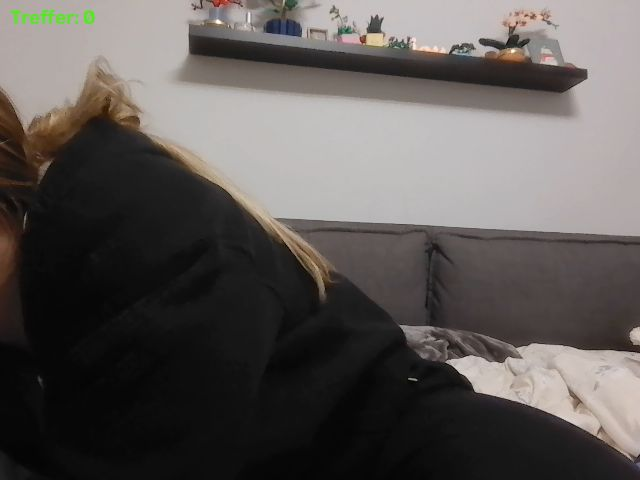

Kamera freigegeben.


In [4]:
if not 0 < CONFIDENCE <= 1:
    raise ValueError("CONFIDENCE muss größer als 0 und höchstens 1 sein.")
if RUN_SECONDS <= 0:
    raise ValueError("RUN_SECONDS muss größer als 0 sein.")

camera = cv2.VideoCapture(CAMERA_INDEX)

try:
    if not camera.isOpened():
        raise RuntimeError(
            f"Kamera {CAMERA_INDEX} konnte nicht geöffnet werden. "
            "Prüfe die Berechtigungen und andere Kamera-Apps "
            "oder versuche CAMERA_INDEX = 1."
        )

    camera.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    camera.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

    preview = display("Kamera gestartet. Warte auf das erste Bild …", display_id=True)
    deadline = monotonic() + RUN_SECONDS
    while monotonic() < deadline:
        success, frame = camera.read()
        if not success or frame is None:
            raise RuntimeError("Die Kamera liefert kein Bild. Öffne sie erneut.")

        result = model.predict(frame, conf=CONFIDENCE, imgsz=640, verbose=False)[0]
        annotated = result.plot(masks=False)
        cv2.putText(
            annotated, f"Treffer: {len(result.boxes)}", (10, 24),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65, (40, 230, 90), 2, cv2.LINE_AA,
        )
        encoded, jpeg = cv2.imencode(".jpg", annotated, [cv2.IMWRITE_JPEG_QUALITY, 80])
        if not encoded:
            raise RuntimeError("Das Kamerabild konnte nicht angezeigt werden.")

        preview.update(Image(data=jpeg.tobytes(), format="jpeg"))

except KeyboardInterrupt:
    pass
finally:
    camera.release()
    print("Kamera freigegeben.")